In [1]:

# ==========================================
# DAY 7 - CELL 24: IMPORT LIBRARIES
# ==========================================

import os
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

from sklearn.exceptions import ConvergenceWarning

os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

RANDOM_STATE = 42

print("Day 7 libraries imported successfully!")


Day 7 libraries imported successfully!


In [2]:

# ==========================================
# DAY 7 - CELL 25: LOAD DATA AND CREATE TARGET
# ==========================================

day7_train = pd.read_csv(
    "../data/processed/train_split.csv"
)

day7_val = pd.read_csv(
    "../data/processed/val_split.csv"
)

day7_test = pd.read_csv(
    "../data/processed/test_split.csv"
)

TARGET = "Units Sold"

for split_name, df in [
    ("train", day7_train),
    ("validation", day7_val),
    ("test", day7_test)
]:
    if TARGET not in df.columns:
        raise ValueError(
            f"{TARGET} is missing from the {split_name} dataset."
        )

    df[TARGET] = pd.to_numeric(
        df[TARGET],
        errors="coerce"
    )

    if df[TARGET].isna().any():
        raise ValueError(
            f"{split_name} contains missing or non-numeric Units Sold. "
            "Resolve these records before continuing."
        )

# Learn class boundaries from training data only
day7_q33 = day7_train[TARGET].quantile(0.33)
day7_q67 = day7_train[TARGET].quantile(0.67)

def day7_make_demand_class(series):
    return pd.Series(
        np.select(
            [
                series <= day7_q33,
                (series > day7_q33) & (series <= day7_q67),
                series > day7_q67
            ],
            ["Low", "Medium", "High"],
            default="Medium"
        ),
        index=series.index
    )

for df in [day7_train, day7_val, day7_test]:
    df["Demand_Class"] = day7_make_demand_class(
        df[TARGET]
    )

print("Train:", day7_train.shape)
print("Validation:", day7_val.shape)
print("Test:", day7_test.shape)

print("\nTraining class distribution:")
display(day7_train["Demand_Class"].value_counts())


Train: (47600, 29)
Validation: (7500, 29)
Test: (7500, 29)

Training class distribution:


Demand_Class
Medium    16092
Low       15846
High      15662
Name: count, dtype: int64

In [3]:

# ==========================================
# DAY 7 - CELL 26: FEATURES AND PREPROCESSING
# ==========================================

excluded_columns = {
    "Date",
    "Store ID",
    "Product ID",
    "Units Sold",
    "Demand_Class",
    "Demand Forecast",
    "Rolling_Mean_7",
    "Rolling_Std_7",
    "Rolling_Mean_28"
}

day7_feature_columns = [
    col for col in day7_train.columns
    if col not in excluded_columns
]

if not day7_feature_columns:
    raise ValueError(
        "No features available after excluding target and ID columns."
    )

day7_X_train = day7_train[day7_feature_columns].copy()
day7_X_val = day7_val.reindex(
    columns=day7_feature_columns
).copy()
day7_X_test = day7_test.reindex(
    columns=day7_feature_columns
).copy()

day7_y_train = day7_train["Demand_Class"].copy()
day7_y_val = day7_val["Demand_Class"].copy()
day7_y_test = day7_test["Demand_Class"].copy()

day7_numeric_features = day7_X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

day7_categorical_features = [
    col for col in day7_X_train.columns
    if col not in day7_numeric_features
]

try:
    day7_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    day7_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

day7_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

day7_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", day7_encoder)
])

day7_transformers = []

if day7_numeric_features:
    day7_transformers.append(
        ("numeric", day7_numeric_pipeline,
         day7_numeric_features)
    )

if day7_categorical_features:
    day7_transformers.append(
        ("categorical", day7_categorical_pipeline,
         day7_categorical_features)
    )

day7_preprocessor = ColumnTransformer(
    transformers=day7_transformers,
    remainder="drop"
)

print("Features used:", day7_feature_columns)
print("\nNumeric features:", day7_numeric_features)
print("\nCategorical features:", day7_categorical_features)


Features used: ['Category', 'Region', 'Inventory Level', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'Is_Weekend', 'Units_Sold_Lag_1', 'Units_Sold_Lag_7', 'Units_Sold_Lag_14', 'Units_Sold_Lag_28']

Numeric features: ['Inventory Level', 'Units Ordered', 'Price', 'Discount', 'Holiday/Promotion', 'Competitor Pricing', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'Is_Weekend', 'Units_Sold_Lag_1', 'Units_Sold_Lag_7', 'Units_Sold_Lag_14', 'Units_Sold_Lag_28']

Categorical features: ['Category', 'Region', 'Weather Condition', 'Seasonality']


In [4]:

# ==========================================
# DAY 7 - CELL 27: ACTIVATION EXPERIMENT
# ==========================================

activation_functions = {
    "Sigmoid": "logistic",
    "Tanh": "tanh",
    "ReLU": "relu"
}

day7_nn_models = {}
day7_nn_results = []

for activation_name, activation_value in activation_functions.items():

    print(f"\nTraining network with {activation_name} activation...")

    nn_pipeline = Pipeline([
        ("preprocessor", day7_preprocessor),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation=activation_value,
            solver="adam",
            alpha=0.0001,
            learning_rate_init=0.001,
            batch_size=256,
            max_iter=300,
            early_stopping=False,
            random_state=RANDOM_STATE
        ))
    ])

    start_time = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        nn_pipeline.fit(day7_X_train, day7_y_train)

    training_seconds = time.perf_counter() - start_time

    val_predictions = nn_pipeline.predict(day7_X_val)

    classifier = nn_pipeline.named_steps["classifier"]

    result = {
        "Activation": activation_name,
        "Accuracy": accuracy_score(
            day7_y_val, val_predictions
        ),
        "Precision_Macro": precision_score(
            day7_y_val,
            val_predictions,
            average="macro",
            zero_division=0
        ),
        "Recall_Macro": recall_score(
            day7_y_val,
            val_predictions,
            average="macro",
            zero_division=0
        ),
        "F1_Macro": f1_score(
            day7_y_val,
            val_predictions,
            average="macro",
            zero_division=0
        ),
        "Training_Seconds": round(training_seconds, 2),
        "Iterations": classifier.n_iter_,
        "Convergence_Warning": any(
            issubclass(w.category, ConvergenceWarning)
            for w in caught_warnings
        )
    }

    day7_nn_models[activation_name] = nn_pipeline
    day7_nn_results.append(result)

    print(
        f"{activation_name}: "
        f"Validation Macro F1 = {result['F1_Macro']:.4f}"
    )

day7_nn_results_df = pd.DataFrame(day7_nn_results)

day7_nn_results_df = day7_nn_results_df.sort_values(
    by="F1_Macro",
    ascending=False
).reset_index(drop=True)

print("\nActivation comparison:")
display(day7_nn_results_df.round(4))



Training network with Sigmoid activation...
Sigmoid: Validation Macro F1 = 0.5525

Training network with Tanh activation...
Tanh: Validation Macro F1 = 0.5197

Training network with ReLU activation...
ReLU: Validation Macro F1 = 0.5159

Activation comparison:


,Activation,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Training_Seconds,Iterations,Convergence_Warning
0,Sigmoid,0.5625,0.5758,0.5609,0.5525,89.37,300,True
1,Tanh,0.5281,0.5222,0.5268,0.5197,96.00,300,True
2,ReLU,0.5248,0.5161,0.5236,0.5159,86.56,300,True


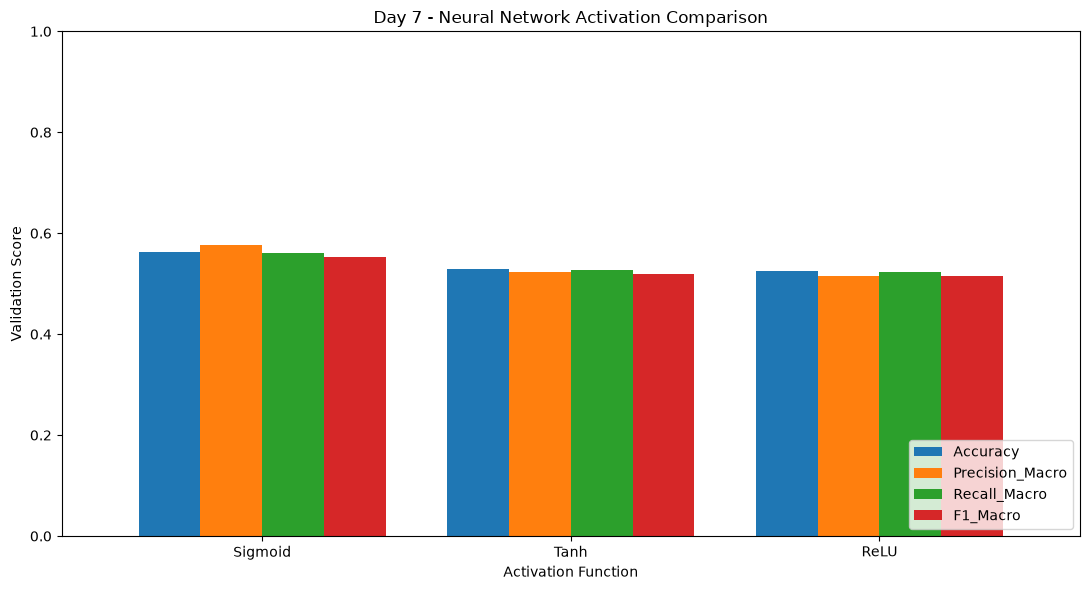

In [5]:

# ==========================================
# DAY 7 - CELL 28: ACTIVATION COMPARISON CHART
# ==========================================

nn_metrics = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro"
]

ax = day7_nn_results_df.set_index("Activation")[
    nn_metrics
].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Day 7 - Neural Network Activation Comparison")
ax.set_xlabel("Activation Function")
ax.set_ylabel("Validation Score")
ax.legend(loc="lower right")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [6]:

# ==========================================
# DAY 7 - CELL 29: FINAL TEST EVALUATION
# ==========================================

best_activation = day7_nn_results_df.iloc[0]["Activation"]
best_nn_model = day7_nn_models[best_activation]

day7_test_predictions = best_nn_model.predict(
    day7_X_test
)

day7_test_results = pd.DataFrame([{
    "Selected_Activation": best_activation,
    "Test_Accuracy": accuracy_score(
        day7_y_test, day7_test_predictions
    ),
    "Test_Precision_Macro": precision_score(
        day7_y_test,
        day7_test_predictions,
        average="macro",
        zero_division=0
    ),
    "Test_Recall_Macro": recall_score(
        day7_y_test,
        day7_test_predictions,
        average="macro",
        zero_division=0
    ),
    "Test_F1_Macro": f1_score(
        day7_y_test,
        day7_test_predictions,
        average="macro",
        zero_division=0
    )
}])

print("Selected activation:", best_activation)
print("\nFinal test metrics:")
display(day7_test_results.round(4))

print("\nDetailed test classification report:")
print(
    classification_report(
        day7_y_test,
        day7_test_predictions,
        labels=["Low", "Medium", "High"],
        zero_division=0
    )
)


Selected activation: Sigmoid

Final test metrics:


,Selected_Activation,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro
0,Sigmoid,0.5456,0.5495,0.5451,0.5389



Detailed test classification report:
              precision    recall  f1-score   support

         Low       0.63      0.46      0.53      2423
      Medium       0.46      0.43      0.44      2555
        High       0.56      0.75      0.64      2522

    accuracy                           0.55      7500
   macro avg       0.55      0.55      0.54      7500
weighted avg       0.55      0.55      0.54      7500

